# Exercise 24 – Molecular dynamics with velocity Verlet

**Week 5 · Molecular dynamics**

Instead of random Monte Carlo moves, molecular dynamics (MD) follows
Newton's equations. The velocity-Verlet integrator

$$x_{n+1} = x_n + v_n\,\Delta t + \tfrac12 a_n \Delta t^2, \qquad
  v_{n+1} = v_n + \tfrac12 (a_n + a_{n+1})\,\Delta t$$

conserves energy very well. A single trajectory at constant energy (NVE) does
**not** sample the Boltzmann distribution, though. To sample at constant
temperature (NVT) we use a simple thermostat: every 50 steps the velocity is
redrawn from the Maxwell–Boltzmann distribution.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from comphy.md import thermostatted_md, velocity_verlet
from comphy.montecarlo import boltzmann_pdf, metropolis

rng = np.random.default_rng(0)
k = 1.0
V = lambda x: 0.5 * k * np.asarray(x) ** 2
force = lambda x: -k * x

## Constant energy (NVE)

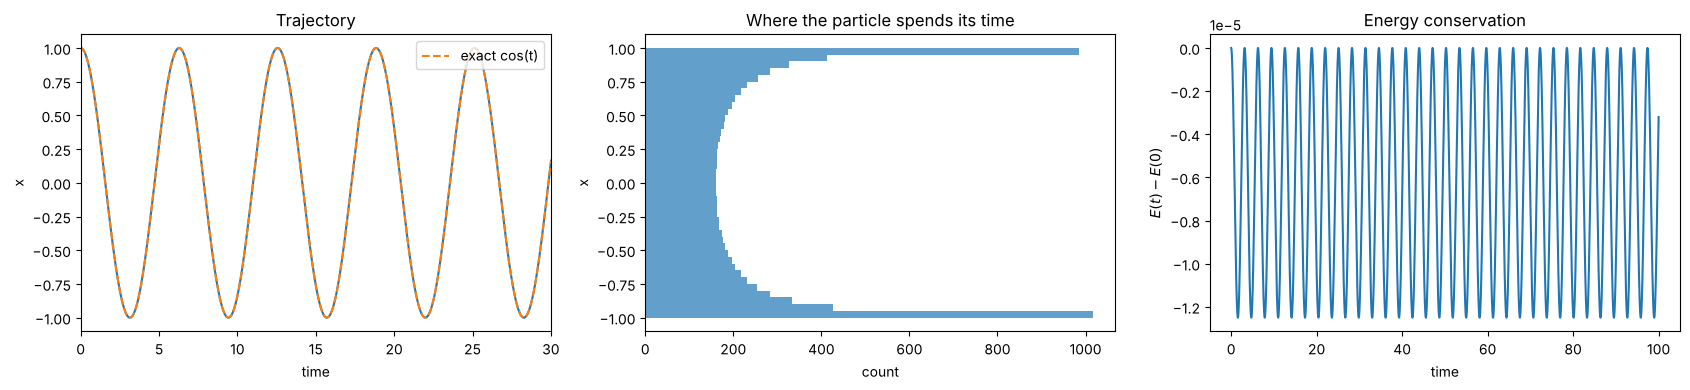

In [2]:
dt, n_steps = 0.01, 10_000
xs, vs = velocity_verlet(1.0, 0.0, force, n_steps, dt=dt)
t = dt * np.arange(n_steps + 1)
energy = V(xs) + 0.5 * vs**2

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot(t, xs)
axes[0].plot(t, np.cos(t), "--", color="C1", label="exact cos(t)")
axes[0].set(xlabel="time", ylabel="x", xlim=(0, 30), title="Trajectory")
axes[0].legend(loc="upper right")
axes[1].hist(xs, bins=40, orientation="horizontal", color="C0", alpha=0.7)
axes[1].set(xlabel="count", ylabel="x", title="Where the particle spends its time")
axes[2].plot(t, energy - energy[0])
axes[2].set(xlabel="time", ylabel="$E(t) - E(0)$", title="Energy conservation")
fig.tight_layout()
plt.show()

The particle oscillates between $\pm 1$ and spends most time near the turning
points – nothing like a Boltzmann distribution. The energy error stays
bounded at the $10^{-5}$ level and does not drift.

## Constant temperature (NVT) – thermostatted MD vs Monte Carlo

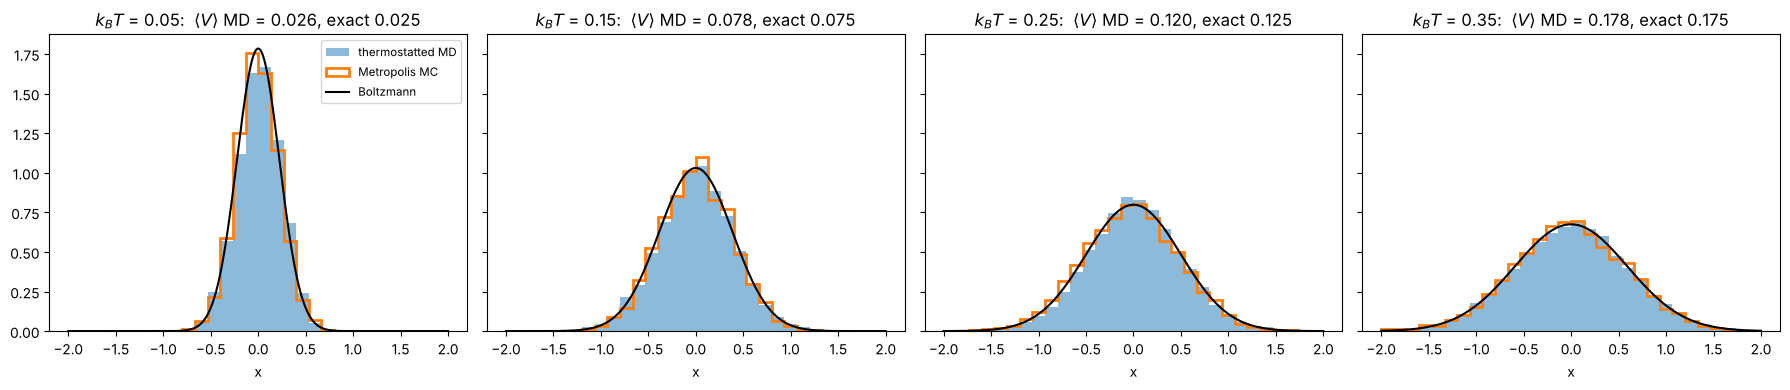

In [3]:
kTs = [0.05, 0.15, 0.25, 0.35]
grid = np.linspace(-2, 2, 400)
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, kT in zip(axes, kTs):
    md_x, _ = thermostatted_md(0.0, force, kT, n_segments=10_000, steps_per_segment=50,
                               dt=0.01, rng=rng)
    mc_x, _ = metropolis(V, kT, x0=0.0, n_steps=10_000, step=0.3, rng=rng)
    ax.hist(md_x, bins=30, range=(-2, 2), density=True, alpha=0.5, label="thermostatted MD")
    ax.hist(mc_x, bins=30, range=(-2, 2), density=True, histtype="step", lw=2, label="Metropolis MC")
    ax.plot(grid, boltzmann_pdf(V, kT, (-3, 3))(grid), color="black", label="Boltzmann")
    ax.set(xlabel="x", title=f"$k_BT$ = {kT}:  ⟨V⟩ MD = {V(md_x).mean():.3f}, "
                             f"exact {kT / 2:.3f}".replace("⟨V⟩", r"$\langle V\rangle$"))
axes[0].legend(fontsize="small")
fig.tight_layout()
plt.show()